# 제조 AI 7주차

### 프로젝트 구조

```text
ManufacturingAI/
├── Secom/
│   ├── secom_X_train.csv
│   ├── secom_X_test.csv
│   ├── secom_y_train.csv
│   └── secom_y_test.csv
├── 제조AI_7주차.ipynb
└── README.md
```

## STEP1 

### SECOM 데이터셋 불러오기 

In [13]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier

import matplotlib.pyplot as plt

import koreanize_matplotlib
plt.rcParams['font.family'] = ['NanumGothic', 'DejaVu Sans']

plt.rcParams['axes.unicode_minus'] = False

from sklearn.metrics import recall_score, precision_score

X_train = pd.read_csv('./Secom/secom_X_train.csv')
X_test = pd.read_csv('./Secom/secom_X_test.csv')
y_train = pd.read_csv('./Secom/secom_y_train.csv').iloc[:, 0]
y_test = pd.read_csv('./Secom/secom_y_test.csv').iloc[:, 0]

print(X_train.shape, X_test.shape)  # 예: (1253, 약 440) / (314, 약 440)
print('test 불량:', y_test.sum(), '/', len(y_test))

(1253, 444) (314, 444)
test 불량: 17 / 314


### XGBoost 분류기를 이용한  불량 판정 모델 학습 및 평가

In [14]:
# 불량(소수 클래스)을 더 중요하게 학습하도록 가중치를 준 XGBoost 분류기
model = XGBClassifier(
    n_estimators=300,       # 학습할 트리 개수
    learning_rate=0.05,     # 각 트리의 기여도
    max_depth=4,            # 트리의 최대 깊이
    scale_pos_weight=13,    # 불량 클래스의 가중치
    random_state=42,         # 실행 결과 재현을 위한 시드
    eval_metric='logloss'   # 학습 중 사용할 평가 지표
)

# 학습 데이터로 모델 학습
model.fit(X_train, y_train)

# 0.5 임계값 대신 예측 확률 상위 15%를 불량 의심군으로 지정
FLAG_RATE = 0.15
proba = model.predict_proba(X_test)[:, 1]  # 각 테스트 샘플의 불량 예측 확률
th = np.percentile(proba, 100 * (1 - FLAG_RATE))  # 상위 15%에 해당하는 확률 임계값
pred = (proba >= th).astype(int)  # 임계값 이상이면 불량 의심(1), 아니면 정상(0)

# 불량 탐지율(Recall)과 불량 판정의 정확도(Precision) 확인
print(f'플래그 임계값(상위 {FLAG_RATE*100:.0f}%): {th:.4f}')
print(
    'test Recall 재확인:',
    round(recall_score(y_test, pred), 3),
    '/ Precision:',
    round(precision_score(y_test, pred, zero_division=0), 3)
)

플래그 임계값(상위 15%): 0.0216
test Recall 재확인: 0.235 / Precision: 0.085


In [15]:
# SHAP(SHapley Additive exPlanations): 각 입력 변수가 모델의 예측에 얼마나 기여했는지 설명하는 기법
import shap
# XGBoost와 같은 트리 기반 모델을 분석하기 위한 SHAP 분석기 생성
explainer = shap.TreeExplainer(model)
# 테스트 데이터의 각 샘플과 입력 변수에 대한 SHAP 값 계산
sv = explainer(X_test)
# SHAP 값의 배열 크기 확인 (샘플 수 × 입력 변수 수)
print('X_test.shape:', X_test.shape)
print('sv.values.shape:', sv.values.shape)    

# SHAP 값 해석
# 양수(+): 불량(1) 예측 방향으로 기여
# 음수(-): 정상(0) 예측 방향으로 기여
# 절댓값이 클수록 해당 예측에 미치는 영향이 큼

X_test.shape: (314, 444)
sv.values.shape: (314, 444)


## STEP 2: 전역적 해석(Global Interpretation) 
모델 전체의 예측 경향을 분석

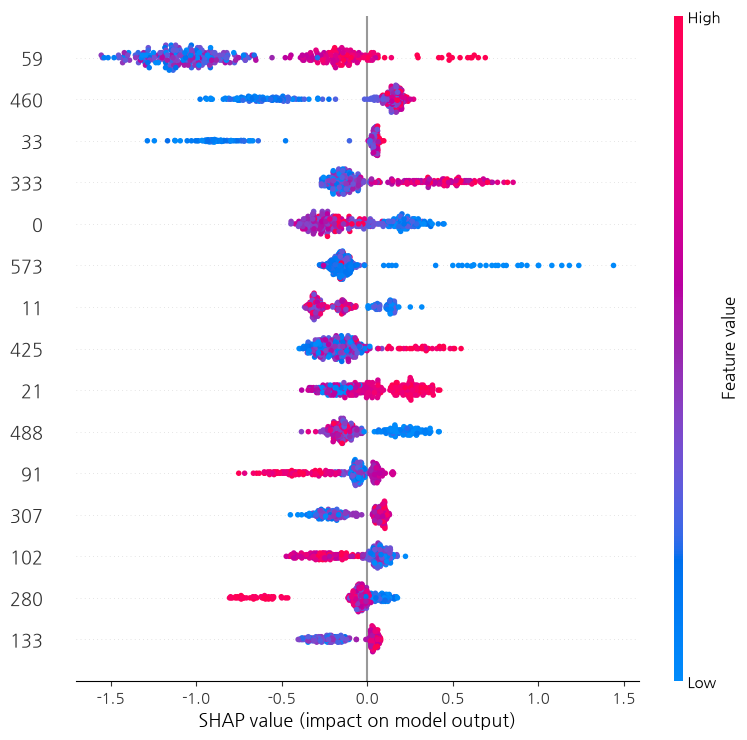

In [16]:
shap.summary_plot(sv, X_test, max_display=15)


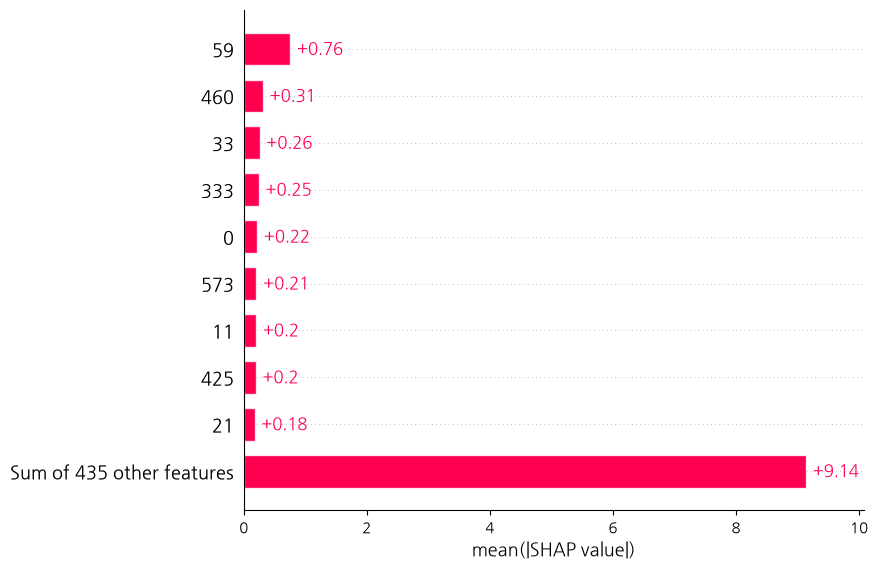

In [17]:
## 어떤 센서가 모델의 예측에 가장 큰 영향을 미쳤는지 확인
shap.plots.bar(sv, max_display=10)


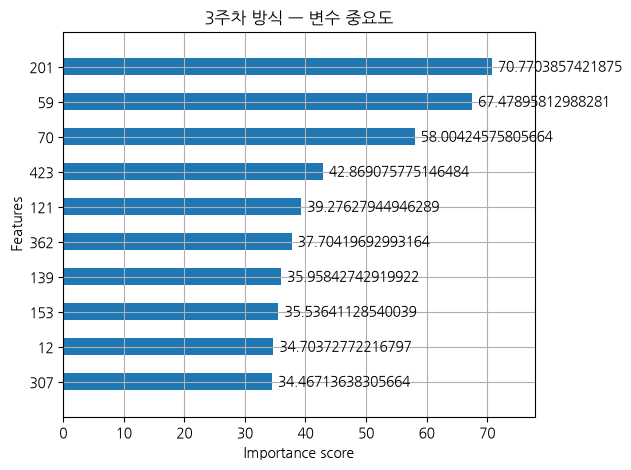

In [18]:
from xgboost import plot_importance


plot_importance(model, max_num_features=10, importance_type='gain', height=0.5)
plt.title('3주차 방식 — 변수 중요도')
plt.tight_layout()
plt.show()

영향력 1위 변수: 59


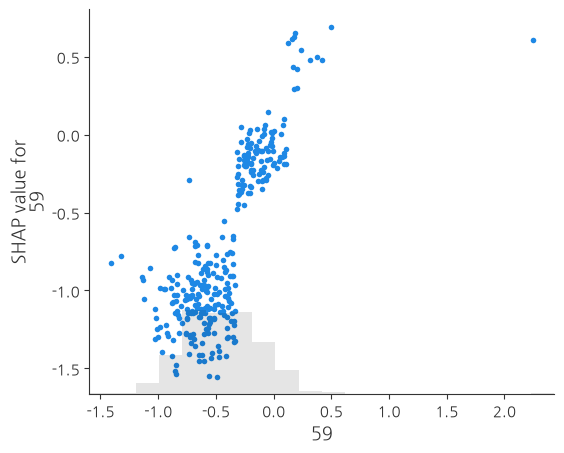

In [19]:
top1 = sv.abs.mean(0).values.argmax() # 영향력 1위 변수의 인덱스
print('영향력 1위 변수:', X_test.columns[top1])
shap.plots.scatter(sv[:, top1]) ## 특정 센서의 측정값과 SHAP 값 사이에 양의 상관관계(Positive Correlation)

## STEP 2: 국소적 해석(Local Interpretation)

특정 제품 하나의 예측 결과를 분석

임계값 0.1: TP  1, FP  7
임계값 0.2: TP  0, FP  3
임계값 0.3: TP  0, FP  2
임계값 0.4: TP  0, FP  2
임계값 0.5: TP  0, FP  1
TP 사례 index=90, 예측 확률=0.0559, 임계값=0.0216


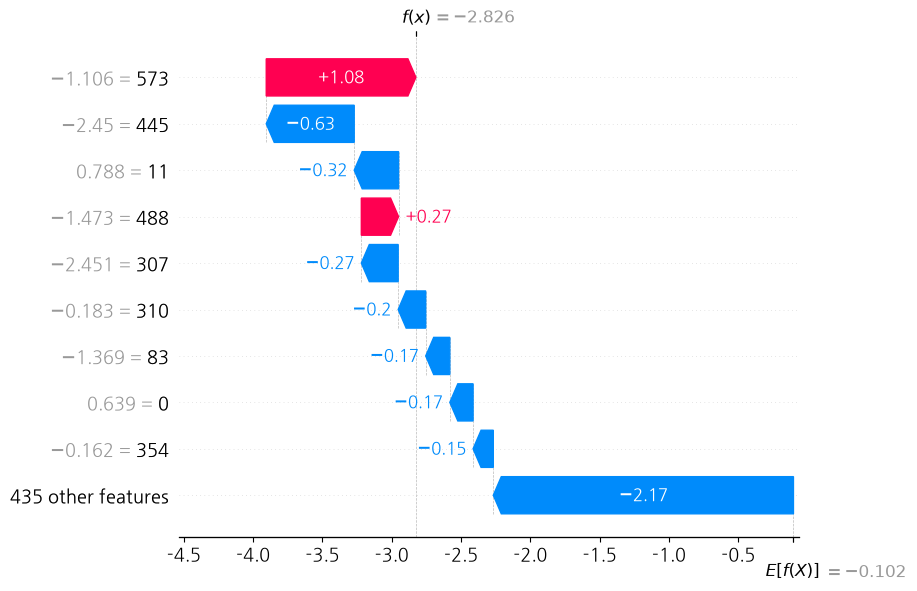

In [20]:
# SHAP Waterfall Plot ①: 실제 불량을 올바르게 예측한 제품(TP)의 예측 근거 분석

# 테스트 데이터의 불량 예측 확률 계산
proba = model.predict_proba(X_test)[:, 1]

# 임계값을 0.1~0.5로 변경하면서 TP와 FP 개수 비교
# TP(True Positive): 실제 불량을 불량으로 올바르게 예측한 경우
# FP(False Positive): 실제 정상을 불량으로 잘못 예측한 경우
for threshold_check in np.arange(0.1, 0.6, 0.1):
    pred_check = proba >= threshold_check
    tp_check = np.sum((y_test.values == 1) & pred_check)
    fp_check = np.sum((y_test.values == 0) & pred_check)
    print(f'임계값 {threshold_check:.1f}: TP {tp_check:2d}, FP {fp_check:2d}')

# 앞서 계산한 상위 15% 기준의 임계값(th)을 사용
# 실제 불량(1)이면서 예측 확률이 임계값 이상인 제품(TP) 검색
threshold = th
tp_idx = np.where((y_test.values == 1) & (proba >= threshold))[0]

if len(tp_idx):
    # TP 사례 중 첫 번째 제품 선택
    idx_tp = int(tp_idx[0])
    print(f'TP 사례 index={idx_tp}, 예측 확률={proba[idx_tp]:.4f}, 임계값={threshold:.4f}')
else:
    # TP가 없으면 실제 불량 제품 중 예측 확률이 가장 높은 제품(FN) 선택
    positive_idx = np.where(y_test.values == 1)[0]
    if not len(positive_idx):
        raise ValueError('테스트 데이터에 실제 불량 사례가 없습니다.')
    idx_tp = int(positive_idx[np.argmax(proba[positive_idx])])
    print(f'TP 없음 — 최고 확률 FN 사례 index={idx_tp}, 예측 확률={proba[idx_tp]:.4f}')

# 선택한 제품의 센서별 SHAP 기여도를 Waterfall Plot으로 시각화
# 빨간색: 불량 예측을 높이는 방향으로 기여
# 파란색: 불량 예측을 낮추는 방향으로 기여
shap.plots.waterfall(sv[idx_tp], max_display=10)

# SHAP 값의 관계: 기준값 E[f(X)] + 각 센서의 SHAP 값 합계 = 최종 모델 출력 f(x)
# 현재 TreeExplainer의 기본 출력은 일반적으로 불량 확률이 아닌 로그 오즈(log-odds)

In [21]:
print(f'실제 레이블: {y_test.iloc[idx_tp]}')
print(f'불량 예측 확률: {proba[idx_tp]:.4f}')
print(f'판정 임계값: {th:.4f}')
print(f'예측 레이블: {int(proba[idx_tp] >= th)}')

실제 레이블: 1
불량 예측 확률: 0.0559
판정 임계값: 0.0216
예측 레이블: 1


FP 사례 index=2, 예측 확률=0.0489, 임계값=0.0216


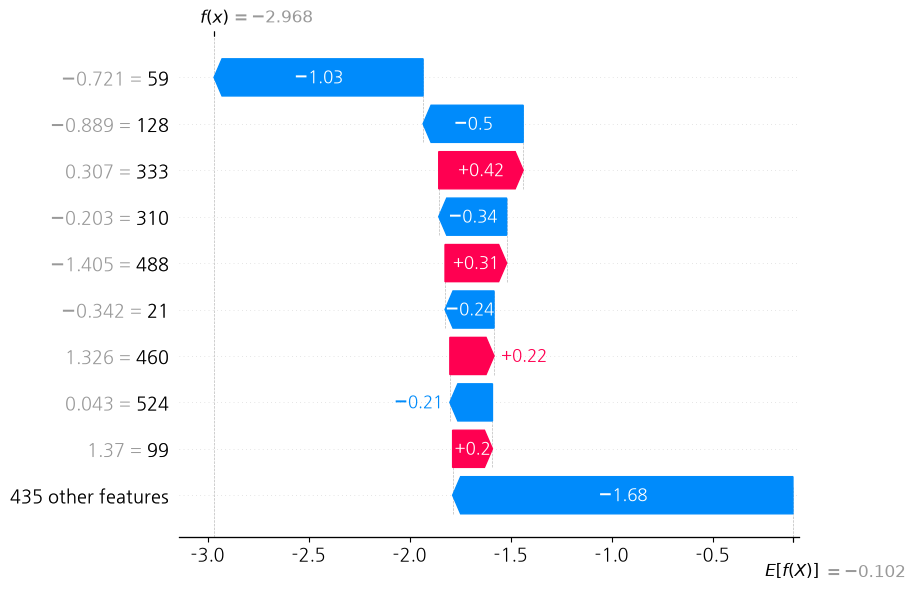

In [22]:
# SHAP Waterfall Plot ②: 정상 제품을 불량으로 잘못 판정한 사례(FP)

# 실제 정상(0)이지만 불량으로 예측한 제품(FP) 검색
fp_idx = np.where((y_test.values == 0) & (proba >= threshold))[0]

if len(fp_idx):
    # FP 사례 중 첫 번째 제품 선택
    idx_fp = int(fp_idx[0])
    print(f'FP 사례 index={idx_fp}, 예측 확률={proba[idx_fp]:.4f}, '
          f'임계값={threshold:.4f}')
else:
    # FP가 없으면 정상 제품 중 불량 예측 확률이 가장 높은 제품 선택
    negative_idx = np.where(y_test.values == 0)[0]
    idx_fp = int(negative_idx[np.argmax(proba[negative_idx])])
    print(f'FP 없음 — 가장 의심스러운 정상 사례 index={idx_fp}, '
          f'예측 확률={proba[idx_fp]:.4f}')

# 선택한 제품의 센서별 SHAP 기여도 시각화
shap.plots.waterfall(sv[idx_fp], max_display=10)

In [23]:
# 현장 번역 미션 — SHAP을 한국어로 (판정 · 근거 상위 3 · 권장 조치)
# idx_tp는 바로 위 TP 셀에서 항상 정의됩니다 (TP 없으면 최고 확률 FN으로 자동 대체)
top3 = np.argsort(-np.abs(sv.values[idx_tp]))[:3]
print(f'[판정] 이 제품은 플래그 기준(상위 15%, {threshold:.4f}) 초과 — 불량 의심군 (확률 {proba[idx_tp]:.4f})')
print('[근거 상위 3]')
for j in top3:
    sign = '+' if sv.values[idx_tp][j] > 0 else '−'
    print(f'  - {X_test.columns[j]}: SHAP {sv.values[idx_tp][j]:+.3f} ({sign} 불량 쪽)' )
print('[권장 조치] 해당 공정 변수 구간 점검 권장 — 인과는 현장 확인 필요')
# ↑ 이 출력을 자연스러운 보고 문장으로 다듬어 보세요 — 발표 "설명 슬라이드"의 원형

[판정] 이 제품은 플래그 기준(상위 15%, 0.0216) 초과 — 불량 의심군 (확률 0.0559)
[근거 상위 3]
  - 573: SHAP +1.080 (+ 불량 쪽)
  - 445: SHAP -0.635 (− 불량 쪽)
  - 11: SHAP -0.320 (− 불량 쪽)
[권장 조치] 해당 공정 변수 구간 점검 권장 — 인과는 현장 확인 필요


In [24]:
# 선택한 제품에서 SHAP 절댓값이 가장 큰 센서 3개 추출
# SHAP 절댓값이 클수록 해당 제품의 예측에 미친 영향이 큼
top3 = np.argsort(-np.abs(sv.values[idx_tp]))[:3]

# 선택한 제품의 불량 예측 확률과 판정 임계값 출력
# 상위 15% 기준의 임계값 이상이면 불량 의심군으로 분류
print(f'[판정] 이 제품은 플래그 기준(상위 15%, {threshold:.4f}) 초과 — 불량 의심군 (확률 {proba[idx_tp]:.4f})')

# 예측에 가장 크게 기여한 센서 3개와 SHAP 값 출력
# SHAP 양수(+): 불량 예측을 높이는 방향으로 기여
# SHAP 음수(-): 불량 예측을 낮추는 방향으로 기여
print('[근거 상위 3]')

for j in top3:
    sign = '+' if sv.values[idx_tp][j] > 0 else '−'
    print(f'  - {X_test.columns[j]}: SHAP {sv.values[idx_tp][j]:+.3f} ({sign} 불량 쪽)' )

# SHAP 분석 결과를 바탕으로 추가 점검 대상 제안
# SHAP은 모델의 예측 근거를 설명하며, 실제 불량 원인을 의미하지는 않음
print('[권장 조치] 해당 공정 변수 구간 점검 권장 — 인과는 현장 확인 필요')


[판정] 이 제품은 플래그 기준(상위 15%, 0.0216) 초과 — 불량 의심군 (확률 0.0559)
[근거 상위 3]
  - 573: SHAP +1.080 (+ 불량 쪽)
  - 445: SHAP -0.635 (− 불량 쪽)
  - 11: SHAP -0.320 (− 불량 쪽)
[권장 조치] 해당 공정 변수 구간 점검 권장 — 인과는 현장 확인 필요


# 과제

이번 주는 별도의 과제 없이, 공유한 Jupyter Notebook을 실행하고 결과를 확인하는 것으로 대체합니다.

실습 내용 (XGBoost 및 SHAP 분석 결과 확인)

1. 공유한 Jupyter Notebook(.ipynb) 실행
2. XGBoost 모델의 예측 결과 확인
3. SHAP 분석 그래프 및 실행 결과 확인
4. 실행한 노트북을 PDF로 변환하여 제출